In [1]:
import pandas as pd
import re
from collections import Counter

# Load dataset
df = pd.read_csv("../data/processed/imdb_reviews.csv")

# Display first 5 rows
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [2]:
# Dataset shape
print("Total Reviews:", df.shape[0])
print("Total Columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate reviews
print("\nDuplicate Reviews:", df.duplicated().sum())

# Sentiment distribution
print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

# Average review length
df["review_length"] = df["review"].apply(lambda x: len(str(x).split()))

print("\nAverage Review Length:", df["review_length"].mean())
print("Shortest Review:", df["review_length"].min())
print("Longest Review:", df["review_length"].max())

Total Reviews: 50000
Total Columns: 2

Column Names:
['review', 'sentiment']

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Reviews: 418

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Average Review Length: 231.15694
Shortest Review: 4
Longest Review: 2470


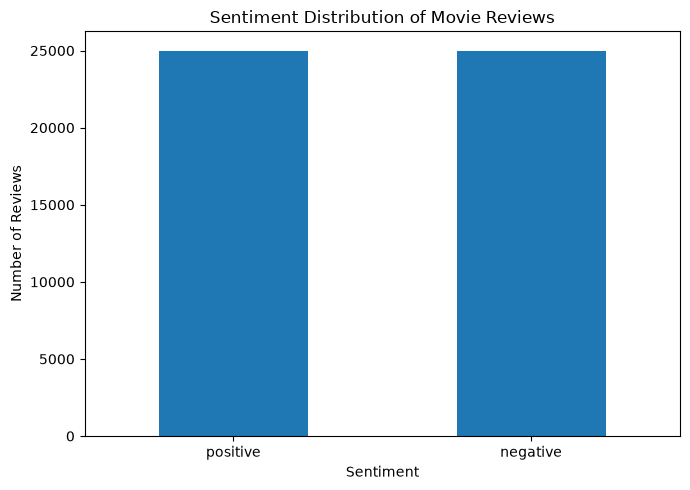

In [3]:
import matplotlib.pyplot as plt

sentiment_counts = df["sentiment"].value_counts()

plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar")

plt.title("Sentiment Distribution of Movie Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
# Analyze vocabulary from first 1000 reviews

sample_reviews = df["review"].head(1000)

tokens = []

for review in sample_reviews:
    words = re.findall(r"\b\w+\b", str(review).lower())
    tokens.extend(words)

total_tokens = len(tokens)
unique_words = len(set(tokens))
type_token_ratio = unique_words / total_tokens

print("Documents Analyzed:", len(sample_reviews))
print("Total Tokens:", total_tokens)
print("Unique Words (Types):", unique_words)
print("Type-Token Ratio:", round(type_token_ratio, 4))

# Most frequent words
word_counts = Counter(tokens)

print("\nTop 10 Most Frequent Words:")
for word, count in word_counts.most_common(10):
    print(word, ":", count)

Documents Analyzed: 1000
Total Tokens: 239546
Unique Words (Types): 17960
Type-Token Ratio: 0.075

Top 10 Most Frequent Words:
the : 13431
and : 6474
a : 6385
of : 5911
to : 5319
br : 4124
is : 4069
in : 3727
it : 3668
i : 3595


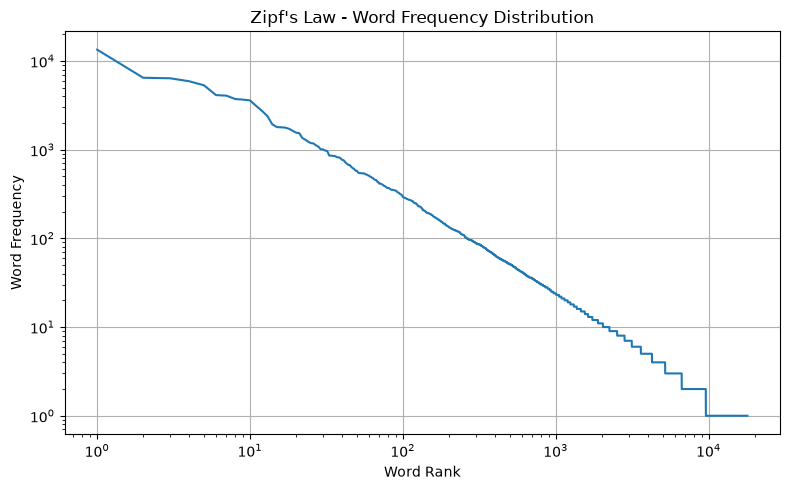

Most Frequent Word: ('the', 13431)
Least Frequent Word Frequency: 1
Total Unique Words: 17960


In [5]:
# Word frequency distribution
frequencies = sorted(word_counts.values(), reverse=True)

ranks = range(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.loglog(ranks, frequencies)

plt.title("Zipf's Law - Word Frequency Distribution")
plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Most Frequent Word:", word_counts.most_common(1)[0])
print("Least Frequent Word Frequency:", min(frequencies))
print("Total Unique Words:", len(frequencies))

In [6]:
# Identify common messy text patterns

sample = df["review"].head(1000)

html_count = sum(
    len(re.findall(r"<br\s*/?>", str(review), flags=re.IGNORECASE))
    for review in sample
)

url_count = sum(
    len(re.findall(r"https?://\S+|www\.\S+", str(review)))
    for review in sample
)

rating_count = sum(
    len(re.findall(r"\b\d+/\d+\b", str(review)))
    for review in sample
)

hyphenated_count = sum(
    len(re.findall(r"\b\w+-\w+\b", str(review)))
    for review in sample
)

print("MESSY TEXT PATTERNS IN FIRST 1000 REVIEWS")
print("HTML break tags:", html_count)
print("URLs:", url_count)
print("Rating expressions:", rating_count)
print("Hyphenated words:", hyphenated_count)

# Display examples
print("\nEXAMPLE 1: HTML tags")
print(sample[sample.str.contains(r"<br\s*/?>", case=False, regex=True)].iloc[0][:300])

print("\nEXAMPLE 2: Contractions")
print(sample[sample.str.contains(r"\b\w+'(?:s|t|re|ve|ll|d|m)\b", case=False, regex=True)].iloc[0][:300])

print("\nEXAMPLE 3: Hyphenated words")
print(sample[sample.str.contains(r"\b\w+-\w+\b", regex=True)].iloc[0][:300])

MESSY TEXT PATTERNS IN FIRST 1000 REVIEWS
HTML break tags: 4124
URLs: 3
Rating expressions: 89
Hyphenated words: 1568

EXAMPLE 1: HTML tags
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru

EXAMPLE 2: Contractions
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru

EXAMPLE 3: Hyphenated words
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <b

## Messy Text Analysis

The first 1000 reviews were analyzed to identify common text preprocessing challenges.

The dataset contains HTML break tags, URLs, rating expressions, contractions, and hyphenated words.

### Observations

1. HTML Tags: 4,124 HTML break tags were found. These tags need to be removed during cleaning.
2. URLs: 3 URLs were detected and should be removed because they do not contribute much to sentiment analysis.
3. Rating Expressions: 89 rating expressions such as 8/10 were identified.
4. Hyphenated Words: 1,568 hyphenated words were found. Tokenization must handle these carefully.

### Dataset-Specific Challenges

- HTML tags can create unnecessary tokens and affect vocabulary statistics.
- Contractions and hyphenated words require careful tokenization to preserve meaningful words.python -c "import fitz; pdf=fitz.open('reports/assignment1_report.pdf'); print('Total PDF Pages:', len(pdf))"